# Figure 8-5 — analytical transfer function

Second-order multiple-feedback low-pass filter published as Figure 8-5 of the
OPA365 datasheet (SBOS365G). The drawing is not reproduced here. The sketch
below is an original figure labeled with the published values.

Published parts: R1 = 549 Ω, R2 = 1.24 kΩ, R3 = 549 Ω, C1 = 1 nF, C2 = 150 pF.
The non-inverting input is grounded. Ideal DC gain is −R3/R1 = −1.

Study assumptions, not printed on the figure: ±2.5 V supplies, 0 V input bias,
±0.1% resistors, ±1% capacitors, 0805 resistors, 50 V capacitors used at half
rating, and a 10 kΩ load.

Created with Grok Build.


In [1]:
import sys

import os
os.environ["MPLBACKEND"] = "Agg"
import matplotlib
matplotlib.use("Agg", force=True)
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import io
from pathlib import Path
from IPython.display import display, Image

def _show(*args, **kwargs):
    buf = io.BytesIO()
    fig = plt.gcf()
    fig.savefig(buf, format="png", dpi=150, bbox_inches="tight")
    plt.close("all")
    display(Image(data=buf.getvalue()))

plt.show = _show

def _find_project_root():
    start = Path.cwd().resolve()
    named = Path("Sections/Electronics/Analog_and_Digital/OPA365_Fig85")
    candidates = [start, *start.parents, start / named]
    if start.name == "notebooks":
        candidates.insert(0, start.parent)
    for cand in candidates:
        if (cand / "mfb_design" / "__init__.py").is_file():
            return cand
    raise FileNotFoundError("mfb_design package was not found")

ROOT = _find_project_root()
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))


In [2]:
from mfb_design.params import CircuitParams, ToleranceSpec

p = CircuitParams(
    R1=549.0,
    R2=1.24e3,
    R3=549.0,
    C1=1.0e-9,
    C2=150.0e-12,
    r_tol=ToleranceSpec(0.001),
    c_tol=ToleranceSpec(0.01),
)
SPICE_WORKERS = 4
N_MC_AC = 2000
N_MC_TRAN = 500
MC_SEED = 42
print(
    f"R1={p.R1:g} ohm  R2={p.R2:g} ohm  R3={p.R3:g} ohm  "
    f"C1={p.C1:g} F  C2={p.C2:g} F"
)
print(
    f"supplies {p.op.v_pos:g} V / {p.op.v_neg:g} V, "
    f"tone {p.op.f_passband_hz:g} Hz, {p.op.v_in_peak:g} V peak"
)
FIG = ROOT / "results" / "figures"
FIG.mkdir(parents=True, exist_ok=True)


R1=549 ohm  R2=1240 ohm  R3=549 ohm  C1=1e-09 F  C2=1.5e-10 F
supplies 2.5 V / -2.5 V, tone 250000 Hz, 1 V peak


## Schematic

VIN feeds R1 into the summing node. C1 goes from that node to ground, R3 feeds
back from the output, and R2 continues into the inverting input. C2 is the
feedback capacitor from the inverting input to the output. This sketch is
drawn by the study. After the LTspice canvas under LTSpice/ is arranged, an
export of that canvas can replace it.


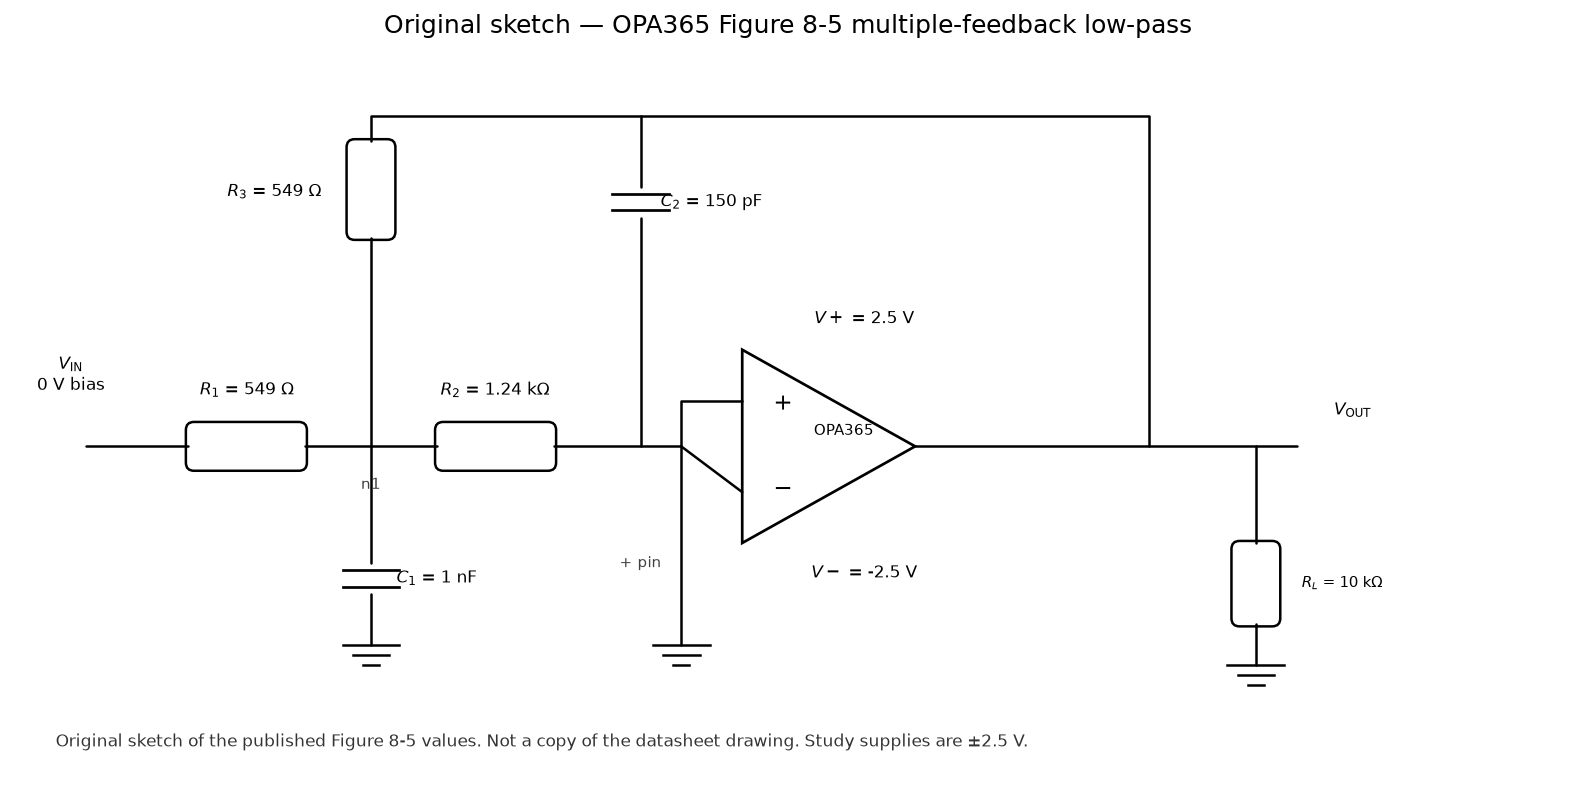

In [3]:
from mfb_design.schematic import draw_fig85_schematic
draw_fig85_schematic(p=p)
plt.show()


## Closed form

With an ideal op-amp and the + pin at ground,

$$
H(s) = \frac{-(1/R_1)}{s^2 C_1 C_2 R_2 + s C_2 R_2 (1/R_1+1/R_2+1/R_3) + 1/R_3}
$$

$$
\omega_0 = 1/\sqrt{R_2 R_3 C_1 C_2}, \qquad
Q = \omega_0 C_1 / (1/R_1+1/R_2+1/R_3), \qquad
H(0) = -R_3/R_1
$$

Q is a little under the Butterworth value 1/√2 because the published E96 and
E12 values do not land on it exactly. The −3 dB frequency is therefore a
little below f0.


In [4]:
from mfb_design.analysis import (
    bode, dc_error_budget, dc_gain, find_fc_3db, format_metrics_table,
    gain_at, latex_transfer_ideal, natural_frequency_hz, quality_factor,
    summary_metrics,
)
from mfb_design.params import format_eng

m = summary_metrics(p)
display(pd.DataFrame(format_metrics_table(m), columns=["metric", "value"]))
print(latex_transfer_ideal(p))
print(
    f"f0 = {natural_frequency_hz(p):.1f} Hz, Q = {quality_factor(p):.4f}, "
    f"Butterworth Q = {1/np.sqrt(2):.4f}, fc = {find_fc_3db(p):.1f} Hz, "
    f"DC gain = {dc_gain(p):.6f}"
)


,metric,value
0,f0,498.1 kHz
1,Q,0.7033
2,f_c (−3 dB),495.4 kHz
3,DC gain,-1.000000
4,|H| at 100 Hz,1.000000
5,|H| at passband tone,0.967223
6,phase at passband tone,136.35°
7,|H| at f_design,0.700572
8,phase at f_design,89.69°
9,DC Vout at bias,0.000000e+00 V


H(s)=\frac{-9.792976e+12}{s^{2} + 4.449439e+06\,s + 9.792976e+12}
f0 = 498055.2 Hz, Q = 0.7033, Butterworth Q = 0.7071, fc = 495372.7 Hz, DC gain = -1.000000


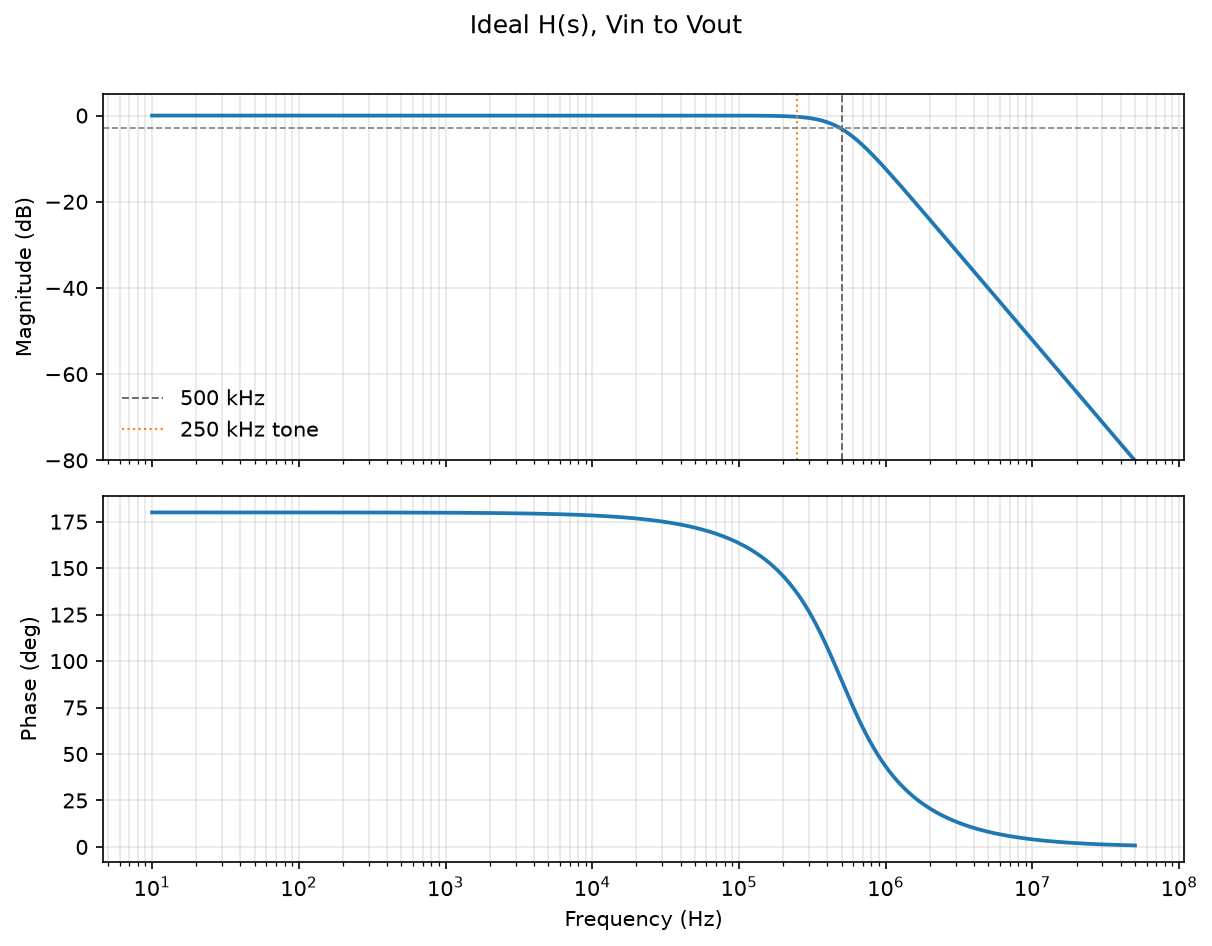

In [5]:
f = np.logspace(np.log10(10), np.log10(50e6), 501)
br = bode(p, source="vin", f_hz=f)
fig, axes = plt.subplots(2, 1, figsize=(8.2, 6.2), sharex=True)
axes[0].semilogx(br.f_hz, br.mag_db, color="C0", lw=1.8)
axes[0].axvline(p.op.f_design_hz, color="0.4", ls="--", lw=0.9, label="500 kHz")
axes[0].axvline(p.op.f_passband_hz, color="C1", ls=":", lw=1.0, label="250 kHz tone")
axes[0].axhline(-3, color="0.5", ls="--", lw=0.8)
axes[0].set_ylabel("Magnitude (dB)")
axes[0].set_ylim(-80, 5)
axes[0].legend(frameon=False)
axes[0].grid(True, which="both", alpha=0.3)
axes[1].semilogx(br.f_hz, br.phase_unwrapped_deg, color="C0", lw=1.8)
axes[1].set_xlabel("Frequency (Hz)")
axes[1].set_ylabel("Phase (deg)")
axes[1].grid(True, which="both", alpha=0.3)
fig.suptitle("Ideal H(s), Vin to Vout", y=1.01)
fig.tight_layout()
plt.show()


## Probes and the four sources

H(0) is exactly −1, so the phase at low frequency is 180°. The passband tone
used later is 250 kHz, one octave below the design frequency.

Vos enters as V(n2) = −Vos, and the DC gain from Vos to Vout is −(1 + R3/R1).
With the published resistors that factor is −2. Ibp does not enter the signal
nodes, because the + pin is grounded. Ibn leaves the inverting node. At DC its
transresistance is R2 + R3 + R2 R3/R1.


In [6]:
rows = []
for freq in (100.0, 1e3, 100e3, 250e3, natural_frequency_hz(p), 500e3, 1e6):
    h = gain_at(p, freq, "vin")
    rows.append({
        "f_Hz": freq,
        "mag": abs(h),
        "mag_dB": 20*np.log10(abs(h)),
        "phase_deg": np.angle(h, deg=True),
    })
display(pd.DataFrame(rows))

vin = 1.0
budget = dc_error_budget(
    p, vin=vin, vos=p.opamp.vos_max, ibp=p.opamp.ib_max, ibn=p.opamp.ib_max,
)
display(pd.DataFrame([budget]))
print(
    "At Vin = 1 V the ideal output is -1 V. "
    f"Vos = +{p.opamp.vos_max*1e6:.0f} µV contributes {budget['due_vos']*1e6:.1f} µV. "
    f"Ibn = +{p.opamp.ib_max*1e12:.0f} pA contributes {budget['due_ibn']*1e9:.3f} nV. "
    f"Ibp contributes {budget['due_ibp']:.3e} V."
)


,f_Hz,mag,mag_dB,phase_deg
0,100.000000,1.000000,-3.782119e-09,179.983643
1,1000.000000,1.000000,-3.782817e-07,179.836434
2,100000.000000,0.998754,-1.082649e-02,163.433924
3,250000.000000,0.967223,-2.894716e-01,136.346270
4,498055.209806,0.703319,-3.056958e+00,90.000000
5,500000.000000,0.700572,-3.090939e+00,89.685913
6,1000000.000000,0.240157,-1.239010e+01,43.282109


,ideal,due_vos,due_ibp,due_ibn,total,error
0,-1.0,-0.0004,0.0,3.029000e-08,-1.0004,-0.0004


At Vin = 1 V the ideal output is -1 V. Vos = +200 µV contributes -400.0 µV. Ibn = +10 pA contributes 30.290 nV. Ibp contributes 0.000e+00 V.
